In [1]:
%matplotlib ipympl

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# setting up logging first or else it gets preempted by another package
import watershed_workflow
watershed_workflow.setupLogging(1)

In [4]:
import os,sys
import logging
import numpy as np
from matplotlib import pyplot as plt
import pickle
import shapely
import pandas as pd
import geopandas as gpd
import xarray as xr
pd.options.display.max_columns = None

import cftime
import datetime

import watershed_workflow 
import watershed_workflow.utils
import watershed_workflow.sources
import watershed_workflow.mesh
import watershed_workflow.properties.land_cover
import watershed_workflow.io

# set the default figure size for notebooks
plt.rcParams["figure.figsize"] = (8, 6)

## Input: Parameters and other source data

In [5]:
# Force Watershed Workflow to pull data from this directory rather than a shared data directory.
# This picks up the Coweeta-specific datasets set up here to avoid large file downloads for 
# demonstration purposes.
#
def splitPathFull(path):
    """
    Splits an absolute path into a list of components such that
    os.path.join(*splitPathFull(path)) == path
    """
    parts = []
    while True:
        head, tail = os.path.split(path)
        if head == path:  # root on Unix or drive letter with backslash on Windows (e.g., C:\)
            parts.insert(0, head)
            break
        elif tail == path:  # just a single file or directory
            parts.insert(0, tail)
            break
        else:
            parts.insert(0, tail)
            path = head
    return parts

cwd = splitPathFull(os.getcwd())
assert cwd[-1] == 'workflow'
cwd = cwd[:-1]

# Note, this directory is where downloaded data will be put as well
data_dir = os.path.join(*(cwd + ['input_data',]))
def toInput(filename):
    return os.path.join(data_dir, filename)

output_filenames = dict()
output_dir = os.path.join(*(cwd + ['output_data',]))
def fromOutput(filename):
    return os.path.join(output_dir, filename)    

def toOutput(role, filename):
    output_filenames[role] = filename
    return fromOutput(filename)

# check output and input dirs exist
if not os.path.isdir(data_dir):
    os.makedirs(data_dir, exist_ok=True)
if not os.path.isdir(output_dir):
    os.makedirs(output_dir, exist_ok=True)
       

In [6]:
# Set the data directory to the local space to get the locally downloaded files
# REMOVE THIS CELL for general use outside fo Coweeta
print(data_dir)
watershed_workflow.utils.setDataDirectory(data_dir)


/Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/input_data


In [7]:
## Parameters cell -- this provides all parameters that can be changed via pipelining to generate a new watershed. 
name = 'RussianRiver'
hucs = ['18010110'] # a list of HUCs to run

# Geometric parameters
# -- parameters to clean and reduce the river network prior to meshing
prune_by_area = 10               # km^2
simplify = 125                   # length scale to target average edge 

# -- mesh triangle refinement control
refine_d0 = 200
refine_d1 = 600

refine_L0 = 125
refine_L1 = 300

refine_A0 = refine_L0**2 / 2
refine_A1 = refine_L1**2 / 2

# Refine triangles if they get too acute
min_angle = 20 # degrees

# width of reach by stream order (order:width)
river_widths = dict({1:10, 2:10, 3:20, 4:30, 5:30}) 


# Note that, by default, we tend to work in the DayMet CRS because this allows us to avoid
# reprojecting meteorological forcing datasets.
crs = watershed_workflow.crs.default_crs


# start and stop time for simulation
# note that this is the overlap of AORC and MODIS
start = cftime.DatetimeGregorian(2007, 8, 1)
end = cftime.DatetimeGregorian(2020, 7, 31)

start_noleap = cftime.DatetimeNoLeap(2007, 8, 1)
end_noleap = cftime.DatetimeNoLeap(2020, 7, 31)
cyclic_nyears = 10


# Global Soil Properties
min_porosity = 0.05 # minimum porosity considered "too small"
max_permeability = 1.e-10 # max value considered "too permeable"
max_vg_alpha = 1.e-3 # max value of van Genuchten's alpha -- our correlation is not valid for some soils


In [8]:
# set up a dictionary of source objects
#
# Data sources, also called managers, deal with downloading and parsing data files from a variety of online APIs.
sources = watershed_workflow.sources.getDefaultSources()

# log the sources that will be used here
watershed_workflow.sources.logSources(sources)


2026-11-13 14:46:31,855 - root - INFO: Using sources:
2026-11-13 14:46:31,855 - root - INFO: --------------
2026-11-13 14:46:31,855 - root - INFO: HUC: ManagerWBD
2026-11-13 14:46:31,856 - root - INFO: hydrography: ManagerNHD
2026-11-13 14:46:31,856 - root - INFO: DEM: Manager3DEP
2026-11-13 14:46:31,856 - root - INFO: soil structure: ManagerNRCS
2026-11-13 14:46:31,856 - root - INFO: geologic structure: ManagerGLHYMPS
2026-11-13 14:46:31,856 - root - INFO: depth to bedrock: ManagerPelletierDTB
2026-11-13 14:46:31,857 - root - INFO: land cover: ManagerNLCD
2026-11-13 14:46:31,857 - root - INFO: LAI: ManagerMODISEarthdata
2026-11-13 14:46:31,857 - root - INFO: meteorology: ManagerAORC
2026-11-13 14:46:31,857 - root - INFO: evapotranspiration: ManagerSSEBop
2026-11-13 14:46:31,857 - root - INFO: observations: ManagerNWIS


## Reload data

In [9]:
with open(fromOutput('02_watersheds.pickle'), 'rb') as fid:
    watersheds = pickle.load(fid)

In [10]:
with open(fromOutput('04_m2.pickle'), 'rb') as fid:
    m2 = pickle.load(fid)


In [11]:
print('2D labeled sets')
print('---------------')
for ls in m2.labeled_sets:
    print(f'{ls.setid} : {ls.entity} : {len(ls.ent_ids)} : "{ls.name}"')

2D labeled sets
---------------
10000 : FACE : 1 : "outlet"
10001 : CELL : 415270 : "Russian"
10002 : CELL : 415270 : "Russian surface"
10003 : FACE : 1903 : "Russian boundary"
10004 : FACE : 9 : "Russian outlet"
10005 : FACE : 9 : "surface domain outlet"
10006 : CELL : 1338 : "stream order 5"
10007 : CELL : 14540 : "stream order 1"
10008 : CELL : 4886 : "stream order 2"
10009 : CELL : 944 : "stream order 4"
10010 : CELL : 2756 : "stream order 3"
10011 : FACE : 3 : "USGS-11461000"
10012 : CELL : 3 : "USGS-11461000 cells"
10013 : FACE : 3 : "USGS-11461500"
10014 : CELL : 3 : "USGS-11461500 cells"
10015 : FACE : 3 : "USGS-11462000"
10016 : CELL : 3 : "USGS-11462000 cells"
10017 : FACE : 3 : "USGS-11462080"
10018 : CELL : 3 : "USGS-11462080 cells"
10019 : FACE : 3 : "USGS-11462500"
10020 : CELL : 3 : "USGS-11462500 cells"
10021 : FACE : 3 : "USGS-11463000"
10022 : CELL : 3 : "USGS-11463000 cells"
10023 : FACE : 3 : "USGS-11463170"
10024 : CELL : 3 : "USGS-11463170 cells"
10025 : FACE : 3 

In [12]:
print(m2.cell_data)

         elevation  partition  land_cover
0       743.951086          0          42
1       665.928867          0          43
2       669.034147          0          52
3       575.347382          0          52
4       608.339242          0          43
...            ...        ...         ...
415265  292.633854       1023          42
415266  272.015092       1023          41
415267  254.436004       1023          52
415268  234.768140       1023          52
415269  216.983663       1023          43

[415270 rows x 3 columns]


## Subsurface Soil, Geologic Structure

### NRCS Soils

In [13]:
# get NRCS shapes, on a reasonable crs
nrcs = sources['soil structure'].getShapesByGeometry(watersheds.df, out_crs=crs)
nrcs

2026-11-13 14:46:33,191 - root - INFO:   Shapes manager: buffered+snapped query box = (-123.391, 38.297000000000004, -122.526, 39.402)
2026-11-13 14:46:33,327 - root - INFO: fixing column: geometry


,mukey,residual saturation [-],Rosetta porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],Rosetta permeability [m^2],thickness [m],permeability [m^2],porosity [-],bulk density [g/cm^3],total sand pct [%],total silt pct [%],total clay pct [%],source,geometry,ID,name
44,458924,0.262417,0.439539,0.000083,1.313487,1.192233e-13,1.370000,2.019751e-13,0.383571,1.416071,29.596429,30.885714,39.517857,NRCS,"MULTIPOLYGON (((-2262309.196 2037766.429, -226...",458924,NRCS-458924
45,458925,0.262417,0.439539,0.000083,1.313487,1.192233e-13,1.370000,2.019751e-13,0.383571,1.416071,29.596429,30.885714,39.517857,NRCS,"MULTIPOLYGON (((-2263876.888 2040204.035, -226...",458925,NRCS-458925
46,458926,0.262417,0.439539,0.000083,1.313487,1.192233e-13,1.370000,2.019751e-13,0.383571,1.416071,29.596429,30.885714,39.517857,NRCS,"MULTIPOLYGON (((-2262179.797 2037258.627, -226...",458926,NRCS-458926
53,458933,0.234447,0.417382,0.000071,1.379255,1.473482e-13,1.470000,2.771209e-13,0.363846,1.397350,35.256410,38.000000,26.743590,NRCS,"MULTIPOLYGON (((-2267471.971 2049579.654, -226...",458933,NRCS-458933
54,458934,0.206665,0.463348,0.000069,1.414206,4.395265e-13,1.503333,3.004872e-13,0.412632,1.190073,40.383887,35.806850,23.809263,NRCS,"MULTIPOLYGON (((-2262599.705 2034820.925, -226...",458934,NRCS-458934
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
797,3115322,0.222654,0.379352,0.000107,1.366197,1.430192e-13,1.371500,1.172957e-12,0.214882,1.530043,49.986016,29.407015,20.606969,NRCS,"MULTIPOLYGON (((-2310349.739 2134033.994, -231...",3115322,NRCS-3115322
798,3251971,0.265837,0.429246,0.000085,1.308479,1.034389e-13,1.882600,1.636090e-13,0.439850,1.449514,31.149190,30.074810,38.776000,NRCS,"MULTIPOLYGON (((-2285692.299 2023919.956, -228...",3251971,NRCS-3251971
799,3251972,0.265837,0.429246,0.000085,1.308479,1.034389e-13,1.882600,1.636090e-13,0.439850,1.449514,31.149190,30.074810,38.776000,NRCS,"MULTIPOLYGON (((-2278859.508 2025515.846, -227...",3251972,NRCS-3251972
800,3251973,0.265668,0.433335,0.000086,1.306383,1.088296e-13,1.857300,1.601528e-13,0.443137,1.440768,31.007334,29.405124,39.587543,NRCS,"MULTIPOLYGON (((-2285034.795 2025528.957, -228...",3251973,NRCS-3251973


In [14]:
# create a clean dataframe with just the data we will need for ATS
def replace_column_nans(df, col_nan, col_replacement):
    """In a df, replace col_nan entries by col_replacement if is nan.  In Place!"""
    row_indexer = df[col_nan].isna()
    df.loc[row_indexer, col_nan] = df.loc[row_indexer, col_replacement]
    return

# where poro or perm is nan, put Rosetta poro
replace_column_nans(nrcs, 'porosity [-]', 'Rosetta porosity [-]')
replace_column_nans(nrcs, 'permeability [m^2]', 'Rosetta permeability [m^2]')

# drop unnecessary columns
for col in ['Rosetta porosity [-]', 'Rosetta permeability [m^2]', 'bulk density [g/cm^3]', 'total sand pct [%]',
            'total silt pct [%]', 'total clay pct [%]']:
    nrcs.pop(col)
    
# drop nans
nan_mask = nrcs.isna().any(axis=1)
dropped_mukeys = nrcs.index[nan_mask]

# Drop those rows
nrcs = nrcs[~nan_mask]

assert nrcs['porosity [-]'][:].min() >= min_porosity
assert nrcs['permeability [m^2]'][:].max() <= max_permeability
nrcs

# check for nans
nrcs.isna().any()

mukey                          False
residual saturation [-]        False
van Genuchten alpha [Pa^-1]    False
van Genuchten n [-]            False
thickness [m]                  False
permeability [m^2]             False
porosity [-]                   False
source                         False
geometry                       False
ID                             False
name                           False
dtype: bool

In [15]:
# drop any duplicates
nrcs = watershed_workflow.properties.soil.dropDuplicates(nrcs, ['ID', 'name', 'mukey'])
nrcs

,residual saturation [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],thickness [m],permeability [m^2],porosity [-],source,ID,name,mukey,geometry
0,0.262417,0.000083,1.313487,1.370000,2.019751e-13,0.383571,NRCS,458924_458925_458926_1607426_1607427_1607428,NRCS-458924_NRCS-458925_NRCS-458926_NRCS-16074...,458924_458925_458926_1607426_1607427_1607428,"MULTIPOLYGON (((-2265003.582 2042770.241, -226..."
1,0.234447,0.000071,1.379255,1.470000,2.771209e-13,0.363846,NRCS,458933,NRCS-458933,458933,"MULTIPOLYGON (((-2267438.371 2049624.854, -226..."
2,0.206665,0.000069,1.414206,1.503333,3.004872e-13,0.412632,NRCS,458934,NRCS-458934,458934,"MULTIPOLYGON (((-2262656.805 2034871.525, -226..."
3,0.208279,0.000071,1.410198,1.504211,3.206068e-13,0.403421,NRCS,458935,NRCS-458935,458935,"MULTIPOLYGON (((-2266272.878 2044358.146, -226..."
4,0.181217,0.000054,1.500531,1.300000,6.489057e-13,0.386277,NRCS,458963_458964_459725_459726,NRCS-458963_NRCS-458964_NRCS-459725_NRCS-459726,458963_458964_459725_459726,"MULTIPOLYGON (((-2268438.927 2026207.727, -226..."
...,...,...,...,...,...,...,...,...,...,...,...
315,0.227798,0.000075,1.385508,0.910000,7.078058e-13,0.363651,NRCS,2747732,NRCS-2747732,2747732,"MULTIPOLYGON (((-2302530.607 2048464.097, -230..."
316,0.218087,0.000085,1.391169,0.580213,8.865366e-13,0.316789,NRCS,3115269_3115293_3115318,NRCS-3115269_NRCS-3115293_NRCS-3115318,3115269_3115293_3115318,"MULTIPOLYGON (((-2309460.417 2129512.048, -230..."
317,0.235420,0.000108,1.338071,1.468500,8.956195e-13,0.273627,NRCS,3115296,NRCS-3115296,3115296,"MULTIPOLYGON (((-2307004.774 2135230.658, -230..."
318,0.265837,0.000085,1.308479,1.882600,1.636090e-13,0.439850,NRCS,3251971_3251972,NRCS-3251971_NRCS-3251972,3251971_3251972,"MULTIPOLYGON (((-2279807.426 2019798.341, -227..."


In [16]:
# Compute the soil color of each cell of the mesh
# We have already merged, so we need to use the current index to set the color and find unique colors.
soil_color_mukey = watershed_workflow.getShapePropertiesOnMesh(m2, nrcs, 'index', 
                                                         resolution=50, nodata=-999)

unique_soil_colors = list(np.unique(soil_color_mukey))
if -999 in unique_soil_colors:
    unique_soil_colors.remove(-999)

# retain only the unique values of soil_color
nrcs = nrcs.loc[unique_soil_colors]

# renumber the ones we know will appear with an ATS ID using ATS conventions
nrcs['TMP_ID'] = nrcs.index
nrcs['ATS ID'] = range(1000, 1000+len(unique_soil_colors))
nrcs.set_index('ATS ID', inplace=True)

# create a new soil color and a soil thickness map using the ATS IDs
soil_color = -np.ones_like(soil_color_mukey)
soil_thickness = np.nan * np.ones(soil_color.shape, 'd')

for ats_ID, ID, thickness in zip(nrcs.index, nrcs.TMP_ID, nrcs['thickness [m]']):
    mask = np.where(soil_color_mukey == ID)
    soil_thickness[mask] = thickness
    soil_color[mask] = ats_ID

# drop the old index; it is no longer needed or useful
nrcs.pop('TMP_ID')

m2.cell_data['soil_color'] = soil_color
m2.cell_data['soil thickness'] = soil_thickness


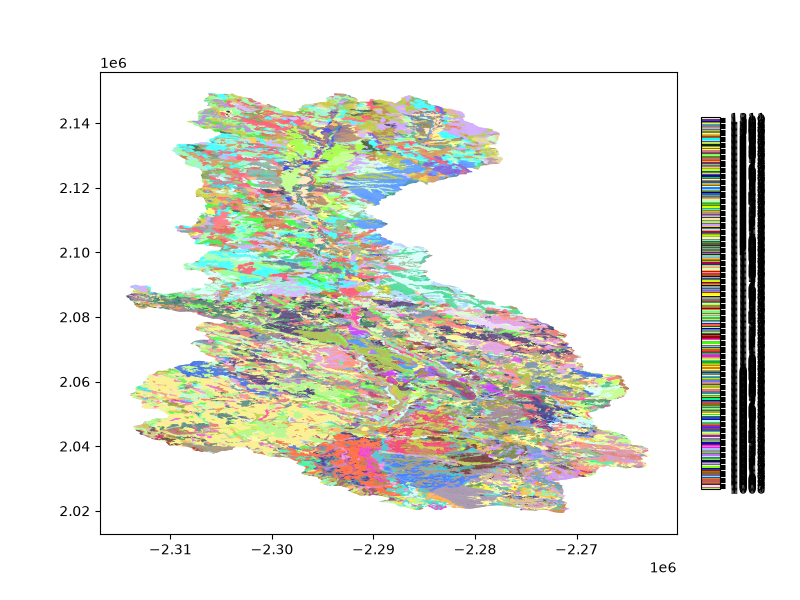

In [17]:
# plot the soil color
# -- get a cmap for soil color
sc_indices, sc_cmap, sc_norm, sc_ticks, sc_labels = \
      watershed_workflow.plot.createIndexedColormap(nrcs.index)

mp = m2.plot(facecolors=m2.cell_data['soil_color'], cmap=sc_cmap, norm=sc_norm, edgecolors=None, colorbar=False)
watershed_workflow.plot.createIndexedColorbar(ncolors=len(nrcs), 
                               cmap=sc_cmap, labels=sc_labels, ax=plt.gca()) 
plt.show()

### Depth to Bedrock from Pelletier

In [18]:
import watershed_workflow.sources.manager_pelletier_dtb

# 1. Define your exact absolute path to the local .tif file
local_dtb_path = "/Users/5n8/Documents/Research_topics/2026_ATS/Maumee_river_basin/Tiffin_river_basin/data/soil_structure/PelletierDTB/Global_Soil_Regolith_Sediment_1304/data/average_soil_and_sedimentary-deposit_thickness.tif"

# 2. Monkey-patch the module-level variable before calling the class!
watershed_workflow.sources.manager_pelletier_dtb._FILENAME = local_dtb_path

# 3. Initialize the manager without arguments (it will now read your custom _FILENAME)
dtb_source = watershed_workflow.sources.manager_pelletier_dtb.ManagerPelletierDTB()

# 4. Extract the dataset 
out = dtb_source.getDataset(watersheds.exterior, watersheds.crs)

dtb = out.get('depth to bedrock', out.get('band_1'))
# dtb = sources['depth to bedrock'].getDataset(watersheds.exterior, watersheds.crs)['band_1']

# # 5. Extract the array securely
# if isinstance(out, dict):
#     dtb = out.get('depth to bedrock', out.get('band_1'))
# else:
#     profile, dtb_data = out
#     dtb = dtb_data[0, :, :] if len(dtb_data.shape) == 3 else dtb_data

print(f"Successfully loaded custom local Pelletier DTB! Shape: {dtb.shape}")

2026-11-13 14:46:45,218 - root - INFO: Incoming shape area = 0.39878167629126127
2026-11-13 14:46:45,219 - root - INFO: ... buffering incoming shape by 3x native resolution = 0.026949335249730505
2026-11-13 14:46:45,229 - root - INFO: ... buffered shape area = 0.509424134505766


Successfully loaded custom local Pelletier DTB! Shape: (140, 110)


In [19]:
# map to the mesh
m2.cell_data['dtb'] = watershed_workflow.getDatasetOnMesh(m2, dtb, method='linear')


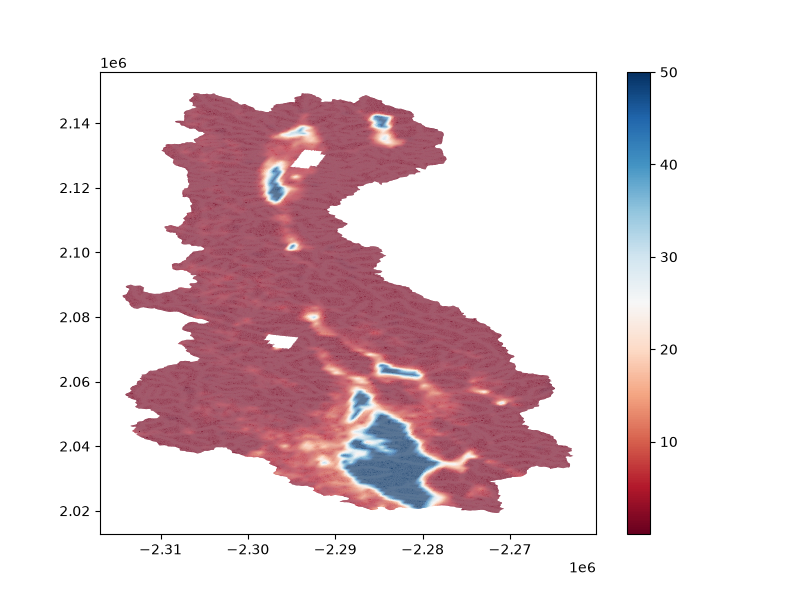

In [20]:
gons = m2.plot(facecolors=m2.cell_data['dtb'], cmap='RdBu', edgecolors=None)
plt.show()

### GLHYMPs Geology

In [21]:
# /Users/5n8/Documents/Research_topics/2026_ATS/Maumee_river_basin/data/soil_structure/GLHYMPS/GLHYMPS.shp
# glhymps = sources['geologic structure'].getShapesByGeometry(watersheds.df, out_crs=crs)
# glhymps = watershed_workflow.properties.soil.mangleGLHYMPSProperties(glhymps,
#                                               min_porosity=min_porosity, 
#                                               max_permeability=max_permeability, 
#                                               max_vg_alpha=max_vg_alpha)

# glhymps

# import watershed_workflow.sources.manager_glhymps

# 1. Define the exact path to your local GLHYMPS shapefile
local_glhymps_path = "/Users/5n8/Documents/Research_topics/2026_ATS/Maumee_river_basin/Tiffin_river_basin/data/soil_structure/GLHYMPS/GLHYMPS.shp"

# 2. Instantiate the manager directly using the 'filename' parameter
local_glhymps_manager = watershed_workflow.sources.manager_glhymps.ManagerGLHYMPS(filename=local_glhymps_path)

# 3. Call getShapesByGeometry on your new local manager instead of the default 'sources' dictionary
glhymps = local_glhymps_manager.getShapesByGeometry(watersheds.df, out_crs=crs)

# 4. (Keep your existing property mangling code exactly the same)
glhymps = watershed_workflow.properties.soil.mangleGLHYMPSProperties(
    glhymps,
    min_porosity=min_porosity,
    max_permeability=max_permeability,
    max_vg_alpha=max_vg_alpha
)

glhymps

2026-11-13 14:46:50,248 - root - INFO:   Shapes manager: buffered+snapped query box = (-13780016.1389586, 3882766.9783805995, -13589684.424332099, 4073098.6930070994)
2026-11-13 14:46:50,249 - root - INFO:   from file: /Users/5n8/Documents/Research_topics/2026_ATS/Maumee_river_basin/Tiffin_river_basin/data/soil_structure/GLHYMPS/GLHYMPS.shp
2026-11-13 14:46:50,334 - root - INFO: fixing column: geometry


,ID,name,source,permeability [m^2],logk_stdev [-],porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-],description,type,geometry
0,1791548,GLHYMPS-1791548,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"POLYGON ((-2283053.622 2139060.084, -2282516.3..."
3,656259,GLHYMPS-656259,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"POLYGON ((-2328113.127 2288102.126, -2328132.8..."
125,657070,GLHYMPS-657070,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"POLYGON ((-2277360.737 2151218.24, -2277494.56..."
142,657155,GLHYMPS-657155,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"POLYGON ((-2281089.624 2139747.911, -2281363.5..."
162,657225,GLHYMPS-657225,GLHYMPS,1.000000e-13,2.00,0.22,0.000294,1.5,0.01,NaN,NaN,"MULTIPOLYGON (((-2286407.211 2139201.695, -228..."
...,...,...,...,...,...,...,...,...,...,...,...,...
882,660184,GLHYMPS-660184,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"POLYGON ((-2274230.82 2029321.201, -2273966.83..."
885,660197,GLHYMPS-660197,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"POLYGON ((-2273434.027 2059196.403, -2273281.2..."
887,660202,GLHYMPS-660202,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"MULTIPOLYGON (((-2247560.765 2001705.928, -224..."
894,660222,GLHYMPS-660222,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"MULTIPOLYGON (((-2292304.841 2139820.097, -229..."


In [22]:
# does the glhymps dataset cover our domain?  NO!
watershed_all = watersheds.exterior

glhymps['geometry'] = glhymps.intersection(watershed_all.buffer(100))
glhymps = glhymps[~(glhymps.geometry.is_empty | glhymps.geometry.isna())]
glhymps_all = glhymps.union_all()

# does the glhymps dataset cover our domain?  NO!
print(glhymps_all.contains(watershed_all))

# what fraction of the area is not covered?  VERY TINY
missing_part = watershed_all - glhymps_all
print('Area fraction of missing areas:', missing_part.area / watershed_all.area)

# what is it? A bunch of small polygons...
print(type(missing_part))
print(len(missing_part.geoms))
print(set(type(p) for p in missing_part.geoms))

False
Area fraction of missing areas: 9.032982161671072e-05
<class 'shapely.geometry.multipolygon.MultiPolygon'>
8
{<class 'shapely.geometry.polygon.Polygon'>}


In [23]:
print(min(glhymps.area))

4.527437655905593


In [24]:
# ok, can we cover them up by buffering each polygon?  Note this will result in overlapping glhymps polygons, but that's ok in this case.
def buffer_by(df : gpd.GeoDataFrame, dist : float) -> gpd.GeoDataFrame:
    """Buffer each geometry in df, but only including the portion of the buffered shape that is not already in the union of all geometries.
    
    Note this results in overlaps where the buffers are both exterior and overlapping.
    """
    df_all = df.union_all()
    new_geometry = [shapely.union(p, p.buffer(dist) - df_all) for p in df.geometry]
    df_copy = df.copy()
    df_copy['geometry'] = new_geometry
    return df_copy


glhymps = buffer_by(glhymps, 1000)
glhymps_all = glhymps.union_all()
print(glhymps_all.contains(watershed_all))
glhymps


True


,ID,name,source,permeability [m^2],logk_stdev [-],porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-],description,type,geometry
0,1791548,GLHYMPS-1791548,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"MULTIPOLYGON (((-2282205.967 2136713.319, -228..."
3,656259,GLHYMPS-656259,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"MULTIPOLYGON (((-2304541.429 2146574.828, -230..."
125,657070,GLHYMPS-657070,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"POLYGON ((-2280210.528 2139776.065, -2280405.7..."
142,657155,GLHYMPS-657155,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"POLYGON ((-2281805.109 2139493.51, -2282235.20..."
162,657225,GLHYMPS-657225,GLHYMPS,1.000000e-13,2.00,0.22,0.000294,1.5,0.01,NaN,NaN,"MULTIPOLYGON (((-2286477.8 2138922.961, -22864..."
...,...,...,...,...,...,...,...,...,...,...,...,...
882,660184,GLHYMPS-660184,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"POLYGON ((-2273663.403 2028624.514, -2273127.6..."
885,660197,GLHYMPS-660197,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"POLYGON ((-2273280.528 2059067.849, -2273099.8..."
887,660202,GLHYMPS-660202,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"MULTIPOLYGON (((-2290832.342 2083524.168, -229..."
894,660222,GLHYMPS-660222,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"MULTIPOLYGON (((-2292008.611 2139057.585, -229..."


In [25]:
# quality check -- make sure glymps shapes cover the watershed
assert glhymps.union_all().contains(watersheds.exterior)
glhymps

,ID,name,source,permeability [m^2],logk_stdev [-],porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-],description,type,geometry
0,1791548,GLHYMPS-1791548,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"MULTIPOLYGON (((-2282205.967 2136713.319, -228..."
3,656259,GLHYMPS-656259,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"MULTIPOLYGON (((-2304541.429 2146574.828, -230..."
125,657070,GLHYMPS-657070,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"POLYGON ((-2280210.528 2139776.065, -2280405.7..."
142,657155,GLHYMPS-657155,GLHYMPS,6.309573e-16,2.50,0.19,0.000025,1.5,0.01,NaN,NaN,"POLYGON ((-2281805.109 2139493.51, -2282235.20..."
162,657225,GLHYMPS-657225,GLHYMPS,1.000000e-13,2.00,0.22,0.000294,1.5,0.01,NaN,NaN,"MULTIPOLYGON (((-2286477.8 2138922.961, -22864..."
...,...,...,...,...,...,...,...,...,...,...,...,...
882,660184,GLHYMPS-660184,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"POLYGON ((-2273663.403 2028624.514, -2273127.6..."
885,660197,GLHYMPS-660197,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"POLYGON ((-2273280.528 2059067.849, -2273099.8..."
887,660202,GLHYMPS-660202,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"MULTIPOLYGON (((-2290832.342 2083524.168, -229..."
894,660222,GLHYMPS-660222,GLHYMPS,3.019952e-11,1.61,0.40,0.001000,1.5,0.01,"Alluvial sediments, thick",Au,"MULTIPOLYGON (((-2292008.611 2139057.585, -229..."


In [26]:
# clean the data
glhymps.pop('logk_stdev [-]')

assert glhymps['porosity [-]'][:].min() >= min_porosity
assert glhymps['permeability [m^2]'][:].max() <= max_permeability
assert glhymps['van Genuchten alpha [Pa^-1]'][:].max() <= max_vg_alpha

glhymps.isna().any()

ID                             False
name                           False
source                         False
permeability [m^2]             False
porosity [-]                   False
van Genuchten alpha [Pa^-1]    False
van Genuchten n [-]            False
residual saturation [-]        False
description                     True
type                            True
geometry                       False
dtype: bool

In [27]:
glhymps = watershed_workflow.properties.soil.dropDuplicates(glhymps, ['ID', 'name'])

In [28]:
assert glhymps.union_all().contains(watersheds.exterior)

In [29]:
# Compute the geo color of each cell of the mesh
geology_color_glhymps = watershed_workflow.getShapePropertiesOnMesh(m2, glhymps, 'index', 
                                                         resolution=50, nodata=-999)

# retain only the unique values of geology that actually appear in our cell mesh
unique_geology_colors = list(np.unique(geology_color_glhymps))
if -999 in unique_geology_colors:
    unique_geology_colors.remove(-999)

# retain only the unique values of geology_color
glhymps = glhymps.loc[unique_geology_colors]

# renumber the ones we know will appear with an ATS ID using ATS conventions
glhymps['ATS ID'] = range(100, 100+len(unique_geology_colors))
glhymps['TMP_ID'] = glhymps.index
glhymps.set_index('ATS ID', drop=True, inplace=True)

# create a new geology color using the ATS IDs
geology_color = -np.ones_like(geology_color_glhymps)
for ats_ID, tmp_ID in zip(glhymps.index, glhymps.TMP_ID):
    geology_color[np.where(geology_color_glhymps == tmp_ID)] = ats_ID

glhymps.pop('TMP_ID')

m2.cell_data['geology_color'] = geology_color
                            

In [30]:
geology_color.min()

np.int64(100)

### Combine to form a complete subsurface dataset

In [31]:
bedrock = watershed_workflow.properties.soil.getDefaultBedrockProperties()

# merge the properties databases
subsurface_props = pd.concat([glhymps, nrcs, bedrock])

# save the properties to disk for use in generating input file
subsurface_props.to_csv(toOutput('subsurface_properties', f'{name}_subsurface_properties.csv'))
subsurface_props


,source,permeability [m^2],porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-],description,type,ID,name,geometry,thickness [m],mukey
ATS ID,,,,,,,,,,,,,
100,GLHYMPS,6.309573e-16,0.190000,0.000025,1.500000,0.010000,NaN,NaN,1791548_656259_657070_657155_657249_657250_657...,GLHYMPS-1791548_GLHYMPS-656259_GLHYMPS-657070_...,"MULTIPOLYGON (((-2308556.954 2043567.216, -230...",NaN,NaN
101,GLHYMPS,1.000000e-13,0.220000,0.000294,1.500000,0.010000,NaN,NaN,657225_657247_657350_657382_657629_657647_6576...,GLHYMPS-657225_GLHYMPS-657247_GLHYMPS-657350_G...,"MULTIPOLYGON (((-2309083.961 2043469.996, -230...",NaN,NaN
102,GLHYMPS,7.943282e-15,0.050000,0.000174,1.500000,0.010000,NaN,NaN,657256_657293_657338_657450_657471_657488_6575...,GLHYMPS-657256_GLHYMPS-657293_GLHYMPS-657338_G...,"MULTIPOLYGON (((-2298487.274 2036254.043, -229...",NaN,NaN
103,GLHYMPS,3.162278e-13,0.270000,0.000472,1.500000,0.010000,NaN,NaN,657277_657308_657457_657787_657820_657824_6579...,GLHYMPS-657277_GLHYMPS-657308_GLHYMPS-657457_G...,"MULTIPOLYGON (((-2296223.667 2108513.491, -229...",NaN,NaN
104,GLHYMPS,3.162278e-13,0.090000,0.000817,1.500000,0.010000,NaN,NaN,657651_657759_657770_657798_657830_657864_6578...,GLHYMPS-657651_GLHYMPS-657759_GLHYMPS-657770_G...,"MULTIPOLYGON (((-2273913.285 2019048.071, -227...",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1308,NRCS,7.078058e-13,0.363651,0.000075,1.385508,0.227798,NaN,NaN,2747732,NRCS-2747732,"MULTIPOLYGON (((-2302530.607 2048464.097, -230...",0.910000,2747732
1309,NRCS,8.865366e-13,0.316789,0.000085,1.391169,0.218087,NaN,NaN,3115269_3115293_3115318,NRCS-3115269_NRCS-3115293_NRCS-3115318,"MULTIPOLYGON (((-2309460.417 2129512.048, -230...",0.580213,3115269_3115293_3115318
1310,NRCS,1.636090e-13,0.439850,0.000085,1.308479,0.265837,NaN,NaN,3251971_3251972,NRCS-3251971_NRCS-3251972,"MULTIPOLYGON (((-2279807.426 2019798.341, -227...",1.882600,3251971_3251972


## Extrude the 2D Mesh to make a 3D mesh

In [32]:
# set the floor of the domain as max DTB
dtb_max = np.nanmax(m2.cell_data['dtb'].values)
m2.cell_data['dtb'] = m2.cell_data['dtb'].fillna(dtb_max)

print(f'total thickness: {dtb_max} m')
total_thickness = 50.


total thickness: 50.0 m


In [33]:
# Generate a dz structure for the top 2m of soil
#
# here we try for 10 cells, starting at 5cm at the top and going to 50cm at the bottom of the 2m thick soil
dzs, res = watershed_workflow.mesh.optimizeDzs(0.05, 0.5, 2, 10)
print(dzs)
print(sum(dzs))

[0.05252036 0.06479527 0.09181838 0.14694819 0.25946146 0.39251928
 0.49439017 0.49754689]
2.0


In [34]:
# this looks like it would work out, with rounder numbers:
dzs_soil = [0.05, 0.05, 0.05, 0.12, 0.23, 0.5, 0.5, 0.5]
print(sum(dzs_soil))

2.0


In [35]:
# 50m total thickness, minus 2m soil thickness, leaves us with 48 meters to make up.
# optimize again...
dzs2, res2 = watershed_workflow.mesh.optimizeDzs(1, 10, 48, 8)
print(dzs2)
print(sum(dzs2))

# how about...
dzs_geo = [1.0, 2.0, 4.0, 8.0, 11, 11, 11]
print(dzs_geo)
print(sum(dzs_geo))

[ 2.71470626  5.85798457  9.42730917 10.         10.         10.        ]
48.0
[1.0, 2.0, 4.0, 8.0, 11, 11, 11]
48.0


In [36]:
print(np.unique(m2.cell_data['soil_color'].to_numpy()))

[  -1 1000 1001 1002 1003 1004 1005 1006 1007 1008 1009 1010 1011 1012
 1013 1014 1015 1016 1017 1018 1019 1020 1021 1022 1023 1024 1025 1026
 1027 1028 1029 1030 1031 1032 1033 1034 1035 1036 1037 1038 1039 1040
 1041 1042 1043 1044 1045 1046 1047 1048 1049 1050 1051 1052 1053 1054
 1055 1056 1057 1058 1059 1060 1061 1062 1063 1064 1065 1066 1067 1068
 1069 1070 1071 1072 1073 1074 1075 1076 1077 1078 1079 1080 1081 1082
 1083 1084 1085 1086 1087 1088 1089 1090 1091 1092 1093 1094 1095 1096
 1097 1098 1099 1100 1101 1102 1103 1104 1105 1106 1107 1108 1109 1110
 1111 1112 1113 1114 1115 1116 1117 1118 1119 1120 1121 1122 1123 1124
 1125 1126 1127 1128 1129 1130 1131 1132 1133 1134 1135 1136 1137 1138
 1139 1140 1141 1142 1143 1144 1145 1146 1147 1148 1149 1150 1151 1152
 1153 1154 1155 1156 1157 1158 1159 1160 1161 1162 1163 1164 1165 1166
 1167 1168 1169 1170 1171 1172 1173 1174 1175 1176 1177 1178 1179 1180
 1181 1182 1183 1184 1185 1186 1187 1188 1189 1190 1191 1192 1193 1194
 1195 

In [37]:
# layer extrusion
DTB = m2.cell_data['dtb'].values
soil_color = m2.cell_data['soil_color'].values
geo_color = m2.cell_data['geology_color'].values
assert min(geo_color) > 0
soil_thickness = m2.cell_data['soil thickness'].values


# -- data structures needed for extrusion
layer_types = []
layer_data = []
layer_ncells = []
layer_mat_ids = []

# -- soil layer --
depth = 0
for dz in dzs_soil:
    depth += 0.5 * dz
    layer_types.append('constant')
    layer_data.append(dz)
    layer_ncells.append(1)
    
    # use glhymps params
    br_or_geo = np.where(depth < DTB, geo_color, 999)
    soil_or_br_or_geo = np.where(np.bitwise_and(soil_color > 0, depth < soil_thickness),
                                 soil_color,
                                 br_or_geo)

    layer_mat_ids.append(soil_or_br_or_geo)
    depth += 0.5 * dz
    
# -- geologic layer --
for dz in dzs_geo:
    depth += 0.5 * dz
    layer_types.append('constant')
    layer_data.append(dz)
    layer_ncells.append(1)
    
    geo_or_br = np.where(depth < DTB, geo_color, 999)

    layer_mat_ids.append(geo_or_br)
    depth += 0.5 * dz

# print the summary
watershed_workflow.Mesh3D.summarizeExtrusion(layer_types, layer_data, 
                                            layer_ncells, layer_mat_ids)

# downselect subsurface properties to only those that are used
layer_mat_id_used = list(np.unique(np.array(layer_mat_ids)))
print('using the following mat ids:', layer_mat_id_used)
subsurface_props_used = subsurface_props.loc[layer_mat_id_used]
subsurface_props_used


2026-11-13 14:46:53,141 - root - INFO: Cell summary:
2026-11-13 14:46:53,142 - root - INFO: ------------------------------------------------------------
2026-11-13 14:46:53,142 - root - INFO: l_id	| c_id	|mat_id	| dz		| z_top
2026-11-13 14:46:53,142 - root - INFO: ------------------------------------------------------------
2026-11-13 14:46:53,142 - root - INFO:  00 	| 00 	| 1252 	|   0.050000 	|   0.000000
2026-11-13 14:46:53,143 - root - INFO:  01 	| 01 	| 1252 	|   0.050000 	|   0.050000
2026-11-13 14:46:53,143 - root - INFO:  02 	| 02 	| 1252 	|   0.050000 	|   0.100000
2026-11-13 14:46:53,143 - root - INFO:  03 	| 03 	| 1252 	|   0.120000 	|   0.150000
2026-11-13 14:46:53,144 - root - INFO:  04 	| 04 	| 1252 	|   0.230000 	|   0.270000
2026-11-13 14:46:53,144 - root - INFO:  05 	| 05 	|  100 	|   0.500000 	|   0.500000
2026-11-13 14:46:53,144 - root - INFO:  06 	| 06 	|  999 	|   0.500000 	|   1.000000
2026-11-13 14:46:53,144 - root - INFO:  07 	| 07 	|  999 	|   0.500000 	|   1.5

using the following mat ids: [np.int64(100), np.int64(101), np.int64(102), np.int64(103), np.int64(104), np.int64(105), np.int64(999), np.int64(1000), np.int64(1001), np.int64(1002), np.int64(1003), np.int64(1004), np.int64(1005), np.int64(1006), np.int64(1007), np.int64(1008), np.int64(1009), np.int64(1010), np.int64(1011), np.int64(1012), np.int64(1013), np.int64(1014), np.int64(1015), np.int64(1016), np.int64(1017), np.int64(1018), np.int64(1019), np.int64(1020), np.int64(1021), np.int64(1022), np.int64(1023), np.int64(1024), np.int64(1025), np.int64(1026), np.int64(1027), np.int64(1028), np.int64(1029), np.int64(1030), np.int64(1031), np.int64(1032), np.int64(1033), np.int64(1034), np.int64(1035), np.int64(1036), np.int64(1037), np.int64(1038), np.int64(1039), np.int64(1040), np.int64(1041), np.int64(1042), np.int64(1043), np.int64(1044), np.int64(1045), np.int64(1046), np.int64(1047), np.int64(1048), np.int64(1049), np.int64(1050), np.int64(1051), np.int64(1052), np.int64(1053), n

,source,permeability [m^2],porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-],description,type,ID,name,geometry,thickness [m],mukey
ATS ID,,,,,,,,,,,,,
100,GLHYMPS,6.309573e-16,0.190000,0.000025,1.500000,0.010000,NaN,NaN,1791548_656259_657070_657155_657249_657250_657...,GLHYMPS-1791548_GLHYMPS-656259_GLHYMPS-657070_...,"MULTIPOLYGON (((-2308556.954 2043567.216, -230...",NaN,NaN
101,GLHYMPS,1.000000e-13,0.220000,0.000294,1.500000,0.010000,NaN,NaN,657225_657247_657350_657382_657629_657647_6576...,GLHYMPS-657225_GLHYMPS-657247_GLHYMPS-657350_G...,"MULTIPOLYGON (((-2309083.961 2043469.996, -230...",NaN,NaN
102,GLHYMPS,7.943282e-15,0.050000,0.000174,1.500000,0.010000,NaN,NaN,657256_657293_657338_657450_657471_657488_6575...,GLHYMPS-657256_GLHYMPS-657293_GLHYMPS-657338_G...,"MULTIPOLYGON (((-2298487.274 2036254.043, -229...",NaN,NaN
103,GLHYMPS,3.162278e-13,0.270000,0.000472,1.500000,0.010000,NaN,NaN,657277_657308_657457_657787_657820_657824_6579...,GLHYMPS-657277_GLHYMPS-657308_GLHYMPS-657457_G...,"MULTIPOLYGON (((-2296223.667 2108513.491, -229...",NaN,NaN
104,GLHYMPS,3.162278e-13,0.090000,0.000817,1.500000,0.010000,NaN,NaN,657651_657759_657770_657798_657830_657864_6578...,GLHYMPS-657651_GLHYMPS-657759_GLHYMPS-657770_G...,"MULTIPOLYGON (((-2273913.285 2019048.071, -227...",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1307,NRCS,4.065767e-13,0.434094,0.000082,1.327769,0.249468,NaN,NaN,813988,NRCS-813988,"MULTIPOLYGON (((-2273006.168 2043175.656, -227...",1.500000,813988
1308,NRCS,7.078058e-13,0.363651,0.000075,1.385508,0.227798,NaN,NaN,2747732,NRCS-2747732,"MULTIPOLYGON (((-2302530.607 2048464.097, -230...",0.910000,2747732
1309,NRCS,8.865366e-13,0.316789,0.000085,1.391169,0.218087,NaN,NaN,3115269_3115293_3115318,NRCS-3115269_NRCS-3115293_NRCS-3115318,"MULTIPOLYGON (((-2309460.417 2129512.048, -230...",0.580213,3115269_3115293_3115318


In [38]:
# extrude
m3 = watershed_workflow.Mesh3D.extruded_Mesh2D(m2, layer_types, layer_data, 
                                             layer_ncells, layer_mat_ids)

In [39]:
print('2D labeled sets')
print('---------------')
for ls in m2.labeled_sets:
    print(f'{ls.setid} : {ls.entity} : {len(ls.ent_ids)} : "{ls.name}"')

print('')
print('Extruded 3D labeled sets')
print('------------------------')
for ls in m3.labeled_sets:
    print(f'{ls.setid} : {ls.entity} : {len(ls.ent_ids)} : "{ls.name}"')

print('')
print('Extruded 3D side sets')
print('---------------------')
for ls in m3.side_sets:
    print(f'{ls.setid} : FACE : {len(ls.cell_list)} : "{ls.name}"')
    

2D labeled sets
---------------
10000 : FACE : 1 : "outlet"
10001 : CELL : 415270 : "Russian"
10002 : CELL : 415270 : "Russian surface"
10003 : FACE : 1903 : "Russian boundary"
10004 : FACE : 9 : "Russian outlet"
10005 : FACE : 9 : "surface domain outlet"
10006 : CELL : 1338 : "stream order 5"
10007 : CELL : 14540 : "stream order 1"
10008 : CELL : 4886 : "stream order 2"
10009 : CELL : 944 : "stream order 4"
10010 : CELL : 2756 : "stream order 3"
10011 : FACE : 3 : "USGS-11461000"
10012 : CELL : 3 : "USGS-11461000 cells"
10013 : FACE : 3 : "USGS-11461500"
10014 : CELL : 3 : "USGS-11461500 cells"
10015 : FACE : 3 : "USGS-11462000"
10016 : CELL : 3 : "USGS-11462000 cells"
10017 : FACE : 3 : "USGS-11462080"
10018 : CELL : 3 : "USGS-11462080 cells"
10019 : FACE : 3 : "USGS-11462500"
10020 : CELL : 3 : "USGS-11462500 cells"
10021 : FACE : 3 : "USGS-11463000"
10022 : CELL : 3 : "USGS-11463000 cells"
10023 : FACE : 3 : "USGS-11463170"
10024 : CELL : 3 : "USGS-11463170 cells"
10025 : FACE : 3 

In [40]:
# save the mesh to disk
output_filenames['mesh'] = toOutput('final mesh', f'{name}-smaller3.exo')
try:
    os.remove(output_filenames['mesh'])
except FileNotFoundError:
    pass
m3.writeExodus(output_filenames['mesh'], element_block_mode="material id")


You are using exodus.py v 1.21.6 (seacas-py3), a python wrapper of some of the exodus library.

Copyright (c) 2013-2023 National Technology &
Engineering Solutions of Sandia, LLC (NTESS).  Under the terms of
Contract DE-NA0003525 with NTESS, the U.S. Government retains certain
rights in this software.

Opening exodus file: /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/output_data/RussianRiver-smaller3.exo


EXODUS: Warning: This code was compiled with exodus version 8.09,
          but was linked with exodus library version 9.06
          This is probably an error in the build process of this code.
2026-11-13 14:49:29,372 - root - INFO: writing partition data as variable
2026-11-13 14:49:29,867 - root - INFO: writing partition data as variable
2026-11-13 14:49:30,634 - root - INFO: writing partition data as variable
2026-11-13 14:49:31,110 - root - INFO: writing partition data as variable
2026-11-13 14:49:31,606 - root - INFO: writing partition data as variable
2026-11-13 14:49:32,552 - root - INFO: writing partition data as variable
2026-11-13 14:49:36,947 - root - INFO: writing partition data as variable
2026-11-13 14:49:37,854 - root - INFO: writing partition data as variable
2026-11-13 14:49:38,359 - root - INFO: writing partition data as variable
2026-11-13 14:49:38,856 - root - INFO: writing partition data as variable
2026-11-13 14:49:39,347 - root - INFO: writing partition data as 

Closing exodus file: /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/output_data/RussianRiver-smaller3.exo


In [41]:
# save labeled set info to disk as well -- just enough for use in input file (we don't need ids)
labeled_sets = [(ls.name, ls.setid, ls.entity) for ls in m3.labeled_sets] + \
               [(ls.name, ls.setid, 'FACE') for ls in m3.side_sets]

with open(toOutput('labeled set metadata', 'ls_metadata.pickle'), 'wb') as fid:
    pickle.dump(labeled_sets, fid)

In [42]:
labeled_sets

[('Russian', 10001, 'CELL'),
 ('bottom', 1, 'FACE'),
 ('surface', 2, 'FACE'),
 ('external sides', 3, 'FACE'),
 ('outlet', 10000, 'FACE'),
 ('Russian surface', 10002, 'FACE'),
 ('Russian boundary', 10003, 'FACE'),
 ('Russian outlet', 10004, 'FACE'),
 ('surface domain outlet', 10005, 'FACE'),
 ('stream order 5', 10006, 'FACE'),
 ('stream order 1', 10007, 'FACE'),
 ('stream order 2', 10008, 'FACE'),
 ('stream order 4', 10009, 'FACE'),
 ('stream order 3', 10010, 'FACE'),
 ('USGS-11461000', 10011, 'FACE'),
 ('USGS-11461000 cells', 10012, 'FACE'),
 ('USGS-11461500', 10013, 'FACE'),
 ('USGS-11461500 cells', 10014, 'FACE'),
 ('USGS-11462000', 10015, 'FACE'),
 ('USGS-11462000 cells', 10016, 'FACE'),
 ('USGS-11462080', 10017, 'FACE'),
 ('USGS-11462080 cells', 10018, 'FACE'),
 ('USGS-11462500', 10019, 'FACE'),
 ('USGS-11462500 cells', 10020, 'FACE'),
 ('USGS-11463000', 10021, 'FACE'),
 ('USGS-11463000 cells', 10022, 'FACE'),
 ('USGS-11463170', 10023, 'FACE'),
 ('USGS-11463170 cells', 10024, 'FACE

In [43]:
# # save the soil properties file
# subsurface_props_used = subsurface_props_used.reset_index(names='ats_id')
# subsurface_props_used.to_csv(toOutput('subsurface properties', '{name}_subsurface_props_used.csv'))

In [44]:
# lastly, reread, update, and output filenames
with open(toOutput('06_output_filenames', '06_output_filenames.txt'), 'wb') as fid:
    pickle.dump(output_filenames, fid)

### Subsurface layers from the MODFLOW input

In [45]:
# # /Users/5n8/Documents/Research_topics/2026_Ethan/input_data/RR_HFM_Shapefiles/RRW_HFMgrid.shp
# import watershed_workflow.sources.manager_shapefile

# # 1. Define the absolute path to your local subsurface shapefile
# subsurface_grid = "/Users/5n8/Documents/Research_topics/2026_Ethan/input_data/RR_HFM_Shapefiles/RRW_HFMgrid.shp"
# model_grid = "/Users/5n8/Documents/Research_topics/2026_Ethan/input_data/model_grid_properties/model_grid_properties.shp"

# # 2. Instantiate the manager directly using the 'filename' parameter
# local_subsurface_manager = watershed_workflow.sources.manager_glhymps.ManagerGLHYMPS(filename=subsurface_grid)
# local_model_manager = watershed_workflow.sources.manager_shapefile.ManagerShapefile(filename=model_grid)

# # 3. Call getShapesByGeometry on your new local manager instead of the default 'sources' dictionary
# subsurface_data = local_subsurface_manager.getShapesByGeometry(watersheds.df, out_crs=crs)
# model_data = local_model_manager.getShapesByGeometry(watersheds.df, out_crs=crs)

# # The output is a standard GeoPandas GeoDataFrame containing your shapes and attributes
# print(f"Successfully loaded {len(subsurface_data)} subsurface features!")
# display(subsurface_data.head())

# display(model_data.head())
# # local_glhymps_path = "/Users/5n8/Documents/Research_topics/2026_ATS/Maumee_river_basin/data/soil_structure/GLHYMPS/GLHYMPS.shp"

# # # 2. Instantiate the manager directly using the 'filename' parameter
# # local_glhymps_manager = watershed_workflow.sources.manager_glhymps.ManagerGLHYMPS(filename=local_glhymps_path)

# # # 3. Call getShapesByGeometry on your new local manager instead of the default 'sources' dictionary
# # glhymps = local_glhymps_manager.getShapesByGeometry(watersheds.df, out_crs=crs)

In [46]:
### Layer thicknesses from the gap-filled rasters
import watershed_workflow.sources.manager_raster

layer1_path = '/Users/5n8/Documents/Research_topics/2026_Ethan/HAND_output/layer1_depth_predicted_filled.tif'
layer2_path = '/Users/5n8/Documents/Research_topics/2026_Ethan/HAND_output/layer2_depth_predicted_filled.tif'
layer3_path = '/Users/5n8/Documents/Research_topics/2026_Ethan/HAND_output/layer3_depth_predicted_filled.tif'

thickness = dict()
for key, path in [('thick_01', layer1_path), ('thick_02', layer2_path), ('thick_03', layer3_path)]:
    # 1. Read the raster clipped to the watershed, same as the Pelletier DTB
    raster_source = watershed_workflow.sources.manager_raster.ManagerRaster(path)
    da = raster_source.getDataset(watersheds.exterior, watersheds.crs)['band_1']

    # 2. The raw reader does not mask NoData, so turn -9999 into NaN before interpolating
    da = da.where(da != da.rio.nodata)

    # 3. Map to the mesh; 'nearest' keeps the 300 m HFM cell values instead of blending across NoData edges
    thickness[key] = np.nan_to_num(watershed_workflow.getDatasetOnMesh(m2, da, method='nearest'), nan=0.0)
    m2.cell_data[key] = thickness[key]
    print(f"{key}: {(thickness[key] > 0).sum()} of {len(thickness[key])} mesh cells > 0, max {thickness[key].max():.1f} m")

t1 = thickness['thick_01']
t2 = thickness['thick_02']
t3 = thickness['thick_03']

# Accumulate the thicknesses to calculate the absolute depth of each layer's bottom boundary
depth_bound_1 = t1
depth_bound_2 = t1 + t2
depth_bound_3 = t1 + t2 + t3


2026-11-13 14:52:59,674 - root - INFO: Incoming shape area = 3843167902.875179
2026-11-13 14:52:59,674 - root - INFO: ... buffering incoming shape by 3x native resolution = 900.0
2026-11-13 14:52:59,680 - root - INFO: ... buffered shape area = 4228970864.405705
2026-11-13 14:52:59,809 - root - INFO: Incoming shape area = 3843167902.875179
2026-11-13 14:52:59,809 - root - INFO: ... buffering incoming shape by 3x native resolution = 900.0
2026-11-13 14:52:59,812 - root - INFO: ... buffered shape area = 4228970864.405705
2026-11-13 14:52:59,920 - root - INFO: Incoming shape area = 3843167902.875179
2026-11-13 14:52:59,920 - root - INFO: ... buffering incoming shape by 3x native resolution = 900.0
2026-11-13 14:52:59,925 - root - INFO: ... buffered shape area = 4228970864.405705


thick_01: 212231 of 415270 mesh cells > 0, max 211.7 m
thick_02: 380901 of 415270 mesh cells > 0, max 220.0 m
thick_03: 412619 of 415270 mesh cells > 0, max 243.3 m


In [47]:
# # 1. Extract the x,y centroids of all 2D mesh cells
# # (m2 is your watershed_workflow 2D mesh object)
# cell_points = gpd.points_from_xy(m2.centroids[:, 0], m2.centroids[:, 1])
# cells_gdf = gpd.GeoDataFrame(geometry=cell_points, crs=m2.crs)

# # 2. Spatially join the cell centers with your thickness polygons
# # Assuming your imported dataframe is named `thickness_gdf`
# cells_with_thick = gpd.sjoin(cells_gdf, model_data, how='left', predicate='intersects')

# # 3. Fill any cells that fall outside the polygons with 0.0 thickness
# cells_with_thick = cells_with_thick.fillna(0.0)

# # 4. Convert the thickness columns to 1D numpy arrays aligned with the mesh
# t1 = cells_with_thick['thick_01'].values
# t2 = cells_with_thick['thick_02'].values
# t3 = cells_with_thick['thick_03'].values

# # 5. Accumulate the thicknesses to calculate the absolute depth of each layer's bottom boundary
# depth_bound_1 = t1
# depth_bound_2 = t1 + t2
# depth_bound_3 = t1 + t2 + t3

In [48]:
# 50m total thickness, minus 2m soil thickness, leaves us with 48 meters to make up.
# optimize again...
# dzs2, res2 = watershed_workflow.mesh.optimizeDzs(1, 10, 48, 8)
# print(dzs2)
# print(sum(dzs2))

# how about...
dzs_geo = [1.0, 2.0, 4.0, 8.0, 11, 11, 11, 20, 30, 50, 50, 50, 50]
print(dzs_geo)
print(sum(dzs_geo))

[1.0, 2.0, 4.0, 8.0, 11, 11, 11, 20, 30, 50, 50, 50, 50]
298.0


In [49]:
# 1. Define the ATS material IDs for your custom subsurface layers
MAT_ID_LAYER1 = 201
MAT_ID_LAYER2 = 202
MAT_ID_LAYER3 = 203
MAT_ID_BEDROCK = 999 

# 2. Extract soil properties from the 2D mesh
soil_color = m2.cell_data['soil_color'].values
soil_thickness = m2.cell_data['soil thickness'].values

# Sanitize any missing soil_color (-1) cells to prevent NaN outputs later
valid_soil_ids = [int(x) for x in np.unique(soil_color) if x > 0]
fallback_soil_id = valid_soil_ids[0] if valid_soil_ids else 999
soil_color = np.where(soil_color == -1, fallback_soil_id, soil_color)

# 3. Calculate absolute depth boundaries by stacking the thicknesses
soil_bottom = soil_thickness
layer1_bottom = soil_bottom + t1
layer2_bottom = layer1_bottom + t2
layer3_bottom = layer2_bottom + t3

# CHANGED: extrude the 2 m soil cells plus the geologic cells, deep enough for the deepest layer 3 bottom
dzs = dzs_soil + dzs_geo
assert sum(dzs) > np.nanmax(layer3_bottom), f"mesh depth {sum(dzs)} m < deepest layer 3 bottom {np.nanmax(layer3_bottom):.1f} m"

# -- data structures needed for extrusion --
layer_types = []
layer_data = []
layer_ncells = []
layer_mat_ids = []

current_depth = 0.0

for dz in dzs:
    # Calculate the depth at the MIDPOINT of the current extrusion cell
    mid_depth = current_depth + 0.5 * dz
    
    layer_types.append('constant')
    layer_data.append(dz)
    layer_ncells.append(1)
    
    # 4. Define the depth conditions for the current cell
    conditions = [
        mid_depth <= soil_bottom,
        mid_depth <= layer1_bottom,
        mid_depth <= layer2_bottom,
        mid_depth <= layer3_bottom
    ]
    
    # 5. Define the corresponding material IDs 
    choices = [
        soil_color,
        MAT_ID_LAYER1,
        MAT_ID_LAYER2,
        MAT_ID_LAYER3
    ]
    
    # 6. Assign the materials. Anything deeper than layer3_bottom defaults to Bedrock.
    mat_ids = np.select(conditions, choices, default=MAT_ID_BEDROCK)
    
    layer_mat_ids.append(mat_ids)
    
    # Advance the current depth to the bottom of this cell for the next loop iteration
    current_depth += dz

# 7. Print the summary and finalize the mesh properties
watershed_workflow.mesh.Mesh3D.summarizeExtrusion(
    layer_types, layer_data, layer_ncells, layer_mat_ids
)

# Bedrock (999) keeps the default bedrock properties already in subsurface_props
geologic_properties = pd.DataFrame({
    'source': 'HFM',
    'name': ['geologic_layer_1', 'geologic_layer_2', 'geologic_layer_3'],
    'porosity [-]': [0.30, 0.25, 0.20],                       # Replace with your actual layer values
    'permeability [m^2]': [1e-12, 1e-13, 5e-14],              # Replace with your actual layer values
    'van Genuchten alpha [Pa^-1]': [1e-4, 1e-4, 1e-5],        # Replace with your actual layer values
    'van Genuchten n [-]': [1.5, 1.4, 1.3],                   # Replace with your actual layer values
    'residual saturation [-]': [0.1, 0.1, 0.15],              # Replace with your actual layer values
}, index=pd.Index([MAT_ID_LAYER1, MAT_ID_LAYER2, MAT_ID_LAYER3], name='ATS ID'))

if 'ATS ID' in subsurface_props.columns:
    subsurface_props = subsurface_props.set_index('ATS ID')

# Add the layer properties, replacing any rows with the same IDs from a previous run
subsurface_props = pd.concat([subsurface_props.drop(geologic_properties.index, errors='ignore'), geologic_properties])

# Downselect subsurface properties to only those that are used
layer_mat_id_used = [int(x) for x in np.unique(np.array(layer_mat_ids))]
subsurface_props_used = subsurface_props.loc[layer_mat_id_used]
display(subsurface_props_used.loc[[MAT_ID_LAYER1, MAT_ID_LAYER2, MAT_ID_LAYER3, MAT_ID_BEDROCK]])


2026-11-13 14:53:00,140 - root - INFO: Cell summary:
2026-11-13 14:53:00,141 - root - INFO: ------------------------------------------------------------
2026-11-13 14:53:00,141 - root - INFO: l_id	| c_id	|mat_id	| dz		| z_top
2026-11-13 14:53:00,141 - root - INFO: ------------------------------------------------------------
2026-11-13 14:53:00,141 - root - INFO:  00 	| 00 	| 1252 	|   0.050000 	|   0.000000
2026-11-13 14:53:00,141 - root - INFO:  01 	| 01 	| 1252 	|   0.050000 	|   0.050000
2026-11-13 14:53:00,141 - root - INFO:  02 	| 02 	| 1252 	|   0.050000 	|   0.100000
2026-11-13 14:53:00,142 - root - INFO:  03 	| 03 	| 1252 	|   0.120000 	|   0.150000
2026-11-13 14:53:00,142 - root - INFO:  04 	| 04 	| 1252 	|   0.230000 	|   0.270000
2026-11-13 14:53:00,142 - root - INFO:  05 	| 05 	|  202 	|   0.500000 	|   0.500000
2026-11-13 14:53:00,143 - root - INFO:  06 	| 06 	|  202 	|   0.500000 	|   1.000000
2026-11-13 14:53:00,143 - root - INFO:  07 	| 07 	|  202 	|   0.500000 	|   1.5

,source,permeability [m^2],porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-],description,type,ID,name,geometry,thickness [m],mukey
ATS ID,,,,,,,,,,,,,
201,HFM,1.000000e-12,0.30,0.000100,1.5,0.10,NaN,NaN,NaN,geologic_layer_1,None,NaN,NaN
202,HFM,1.000000e-13,0.25,0.000100,1.4,0.10,NaN,NaN,NaN,geologic_layer_2,None,NaN,NaN
203,HFM,5.000000e-14,0.20,0.000010,1.3,0.15,NaN,NaN,NaN,geologic_layer_3,None,NaN,NaN
999,n/a,1.000000e-16,0.05,0.000019,1.5,0.01,NaN,NaN,999,bedrock,None,NaN,NaN


In [50]:
# extrude
m3_mod = watershed_workflow.Mesh3D.extruded_Mesh2D(m2, layer_types, layer_data, 
                                             layer_ncells, layer_mat_ids)

In [51]:
print('2D labeled sets')
print('---------------')
for ls in m2.labeled_sets:
    print(f'{ls.setid} : {ls.entity} : {len(ls.ent_ids)} : "{ls.name}"')

print('')
print('Extruded 3D labeled sets')
print('------------------------')
for ls in m3_mod.labeled_sets:
    print(f'{ls.setid} : {ls.entity} : {len(ls.ent_ids)} : "{ls.name}"')

print('')
print('Extruded 3D side sets')
print('---------------------')
for ls in m3_mod.side_sets:
    print(f'{ls.setid} : FACE : {len(ls.cell_list)} : "{ls.name}"')
    

2D labeled sets
---------------
10000 : FACE : 1 : "outlet"
10001 : CELL : 415270 : "Russian"
10002 : CELL : 415270 : "Russian surface"
10003 : FACE : 1903 : "Russian boundary"
10004 : FACE : 9 : "Russian outlet"
10005 : FACE : 9 : "surface domain outlet"
10006 : CELL : 1338 : "stream order 5"
10007 : CELL : 14540 : "stream order 1"
10008 : CELL : 4886 : "stream order 2"
10009 : CELL : 944 : "stream order 4"
10010 : CELL : 2756 : "stream order 3"
10011 : FACE : 3 : "USGS-11461000"
10012 : CELL : 3 : "USGS-11461000 cells"
10013 : FACE : 3 : "USGS-11461500"
10014 : CELL : 3 : "USGS-11461500 cells"
10015 : FACE : 3 : "USGS-11462000"
10016 : CELL : 3 : "USGS-11462000 cells"
10017 : FACE : 3 : "USGS-11462080"
10018 : CELL : 3 : "USGS-11462080 cells"
10019 : FACE : 3 : "USGS-11462500"
10020 : CELL : 3 : "USGS-11462500 cells"
10021 : FACE : 3 : "USGS-11463000"
10022 : CELL : 3 : "USGS-11463000 cells"
10023 : FACE : 3 : "USGS-11463170"
10024 : CELL : 3 : "USGS-11463170 cells"
10025 : FACE : 3 

In [52]:
# save the mesh to disk
output_filenames['mesh'] = toOutput('final mesh', f'{name}-smaller3_mod.exo')
try:
    os.remove(output_filenames['mesh'])
except FileNotFoundError:
    pass
m3_mod.writeExodus(output_filenames['mesh'], element_block_mode="material id")

Opening exodus file: /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/output_data/RussianRiver-smaller3_mod.exo


2026-11-13 14:58:18,328 - root - INFO: writing partition data as variable
2026-11-13 14:58:26,560 - root - INFO: writing partition data as variable
2026-11-13 14:58:35,193 - root - INFO: writing partition data as variable
2026-11-13 14:58:44,159 - root - INFO: writing partition data as variable
2026-11-13 14:58:45,821 - root - INFO: writing partition data as variable
2026-11-13 14:58:46,620 - root - INFO: writing partition data as variable
2026-11-13 14:58:47,357 - root - INFO: writing partition data as variable
2026-11-13 14:58:54,037 - root - INFO: writing partition data as variable
2026-11-13 14:58:54,768 - root - INFO: writing partition data as variable
2026-11-13 14:58:55,508 - root - INFO: writing partition data as variable
2026-11-13 14:58:56,219 - root - INFO: writing partition data as variable
2026-11-13 14:58:56,925 - root - INFO: writing partition data as variable
2026-11-13 14:58:57,637 - root - INFO: writing partition data as variable
2026-11-13 14:58:58,350 - root - INFO:

Closing exodus file: /Users/5n8/Documents/Research_topics/2026_Ethan/PacWest-RDT-main/RussianRiver3/output_data/RussianRiver-smaller3_mod.exo


In [53]:
bedrock = watershed_workflow.properties.soil.getDefaultBedrockProperties()

# merge the properties databases
subsurface_props = pd.concat([glhymps, nrcs, bedrock])

# save the properties to disk for use in generating input file
subsurface_props.to_csv(toOutput('subsurface_properties', f'{name}_subsurface_properties.csv'))
subsurface_props

,source,permeability [m^2],porosity [-],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-],description,type,ID,name,geometry,thickness [m],mukey
ATS ID,,,,,,,,,,,,,
100,GLHYMPS,6.309573e-16,0.190000,0.000025,1.500000,0.010000,NaN,NaN,1791548_656259_657070_657155_657249_657250_657...,GLHYMPS-1791548_GLHYMPS-656259_GLHYMPS-657070_...,"MULTIPOLYGON (((-2308556.954 2043567.216, -230...",NaN,NaN
101,GLHYMPS,1.000000e-13,0.220000,0.000294,1.500000,0.010000,NaN,NaN,657225_657247_657350_657382_657629_657647_6576...,GLHYMPS-657225_GLHYMPS-657247_GLHYMPS-657350_G...,"MULTIPOLYGON (((-2309083.961 2043469.996, -230...",NaN,NaN
102,GLHYMPS,7.943282e-15,0.050000,0.000174,1.500000,0.010000,NaN,NaN,657256_657293_657338_657450_657471_657488_6575...,GLHYMPS-657256_GLHYMPS-657293_GLHYMPS-657338_G...,"MULTIPOLYGON (((-2298487.274 2036254.043, -229...",NaN,NaN
103,GLHYMPS,3.162278e-13,0.270000,0.000472,1.500000,0.010000,NaN,NaN,657277_657308_657457_657787_657820_657824_6579...,GLHYMPS-657277_GLHYMPS-657308_GLHYMPS-657457_G...,"MULTIPOLYGON (((-2296223.667 2108513.491, -229...",NaN,NaN
104,GLHYMPS,3.162278e-13,0.090000,0.000817,1.500000,0.010000,NaN,NaN,657651_657759_657770_657798_657830_657864_6578...,GLHYMPS-657651_GLHYMPS-657759_GLHYMPS-657770_G...,"MULTIPOLYGON (((-2273913.285 2019048.071, -227...",NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1308,NRCS,7.078058e-13,0.363651,0.000075,1.385508,0.227798,NaN,NaN,2747732,NRCS-2747732,"MULTIPOLYGON (((-2302530.607 2048464.097, -230...",0.910000,2747732
1309,NRCS,8.865366e-13,0.316789,0.000085,1.391169,0.218087,NaN,NaN,3115269_3115293_3115318,NRCS-3115269_NRCS-3115293_NRCS-3115318,"MULTIPOLYGON (((-2309460.417 2129512.048, -230...",0.580213,3115269_3115293_3115318
1310,NRCS,1.636090e-13,0.439850,0.000085,1.308479,0.265837,NaN,NaN,3251971_3251972,NRCS-3251971_NRCS-3251972,"MULTIPOLYGON (((-2279807.426 2019798.341, -227...",1.882600,3251971_3251972


### Checks to confirm the layer thicknesses are included from the data provided

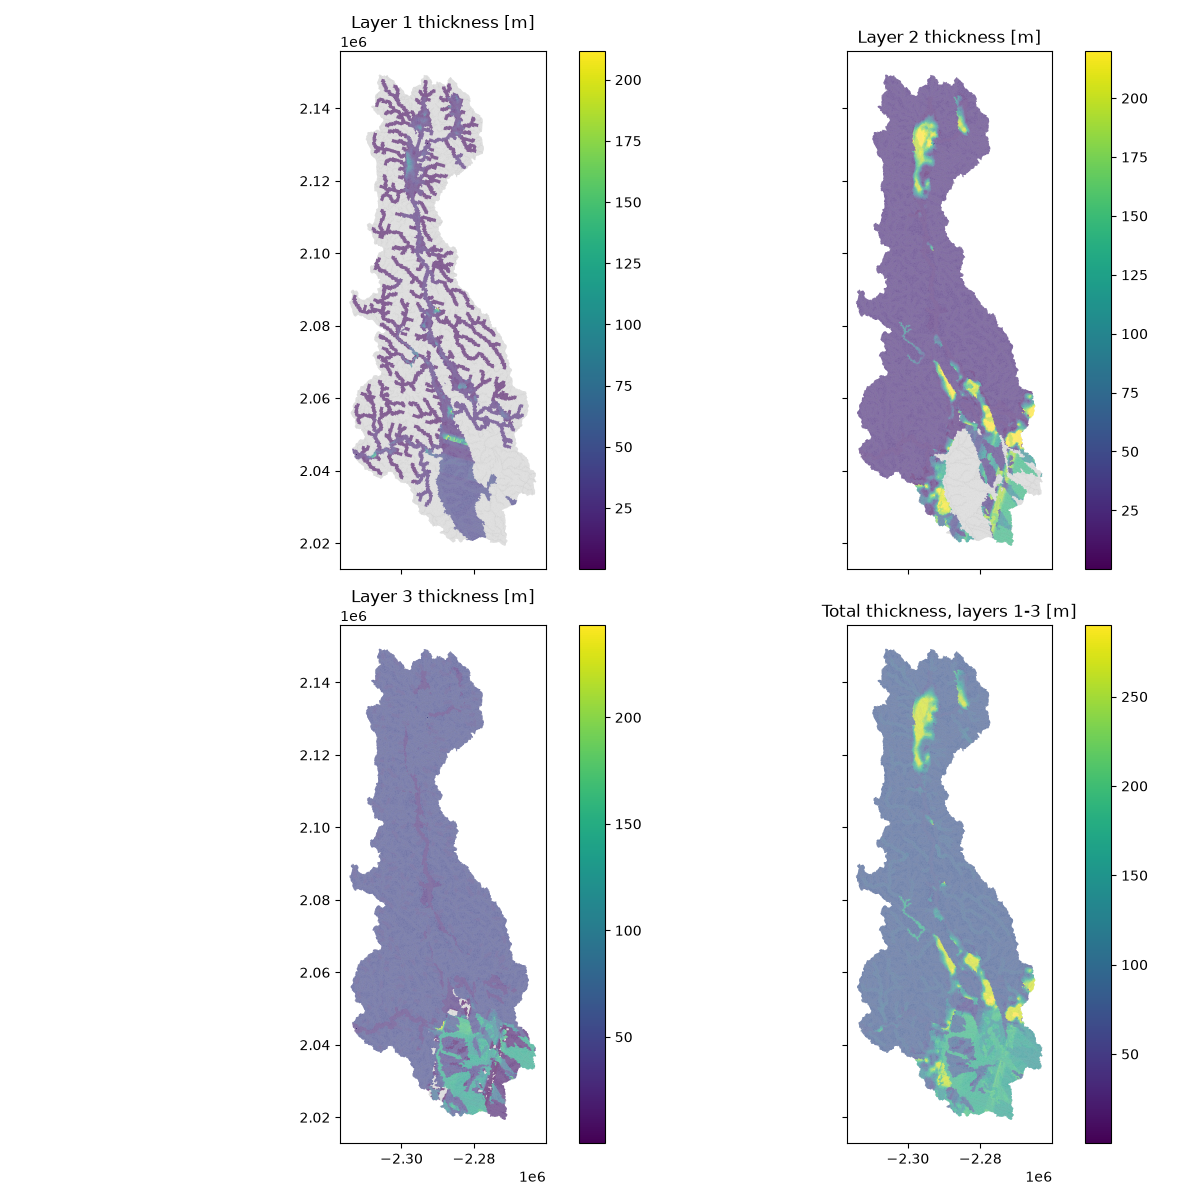

In [54]:
### Map the layer thicknesses on the 2D mesh

fig, axs = plt.subplots(2, 2, figsize=(12, 12), sharex=True, sharey=True)
for ax, (title, values) in zip(axs.flat, [('Layer 1 thickness [m]', t1),
                                         ('Layer 2 thickness [m]', t2),
                                         ('Layer 3 thickness [m]', t3),
                                         ('Total thickness, layers 1-3 [m]', t1 + t2 + t3)]):
    # Zero thickness is drawn in grey so the absent parts of a layer stand out
    cmap = plt.colormaps['viridis'].copy()
    cmap.set_under('lightgrey')
    m2.plot(facecolors=values, ax=ax, cmap=cmap, vmin=0.01, edgecolors='none')
    ax.set_title(title)
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()


In [55]:
### Check the extruded mesh: thickness of each material in every column vs t1, t2, t3

dz_cells = np.array(layer_data, dtype=float)
mesh_depth = dz_cells.sum()

# material_ids are ordered column by column, top to bottom: id = z_cell + column * ncells_tall
mat_cols = np.asarray(m3_mod.material_ids).reshape(m2.num_cells, len(dz_cells))

# Cell counts per material ID, and whether every ID has a row in the properties table
ids, counts = np.unique(mat_cols, return_counts=True)
print(f"Mesh: {m2.num_cells} columns x {len(dz_cells)} cells = {mat_cols.size} cells, domain depth {mesh_depth:.1f} m")
for mat_id in [MAT_ID_LAYER1, MAT_ID_LAYER2, MAT_ID_LAYER3, MAT_ID_BEDROCK]:
    print(f"  ID {mat_id}: {counts[ids == mat_id].sum()} cells")
print(f"  soil IDs: {counts[~np.isin(ids, [MAT_ID_LAYER1, MAT_ID_LAYER2, MAT_ID_LAYER3, MAT_ID_BEDROCK])].sum()} cells")
missing = [int(i) for i in ids if i not in subsurface_props_used.index or subsurface_props_used.loc[i].isna().all()]
print(f"Material IDs without properties: {missing if missing else 'none'}")

# Thickness the mesh gives each layer in every column, compared with the requested thickness
# Differences up to one dz are expected: a cell takes the material at its midpoint depth
print(f"\n{'layer':<8}{'requested>0':>13}{'in mesh>0':>11}{'median |diff| [m]':>19}{'max |diff| [m]':>16}")
for name, mat_id, requested in [('layer 1', MAT_ID_LAYER1, t1), ('layer 2', MAT_ID_LAYER2, t2), ('layer 3', MAT_ID_LAYER3, t3)]:
    meshed = ((mat_cols == mat_id) * dz_cells).sum(axis=1)
    diff = np.abs(meshed - requested)
    print(f"{name:<8}{(requested > 0).sum():>13}{(meshed > 0).sum():>11}{np.median(diff):>19.2f}{diff.max():>16.2f}")

# Columns where soil + layers 1-3 reach below the bottom of the mesh are cut off
truncated = layer3_bottom > mesh_depth
print(f"\nColumns where layer 3 extends below the mesh bottom ({mesh_depth:.0f} m): {truncated.sum()} "
      f"(deepest layer 3 bottom: {layer3_bottom.max():.1f} m)")


Mesh: 415270 columns x 21 cells = 8720670 cells, domain depth 300.0 m
  ID 201: 1038644 cells
  ID 202: 1922642 cells
  ID 203: 1080660 cells
  ID 999: 2038576 cells
  soil IDs: 2640148 cells
Material IDs without properties: none

layer     requested>0  in mesh>0  median |diff| [m]  max |diff| [m]
layer 1        212231     202696               0.20          193.30
layer 2        380901     368046               2.50          220.00
layer 3        412619     389063               8.00          163.12

Columns where layer 3 extends below the mesh bottom (300 m): 0 (deepest layer 3 bottom: nan m)


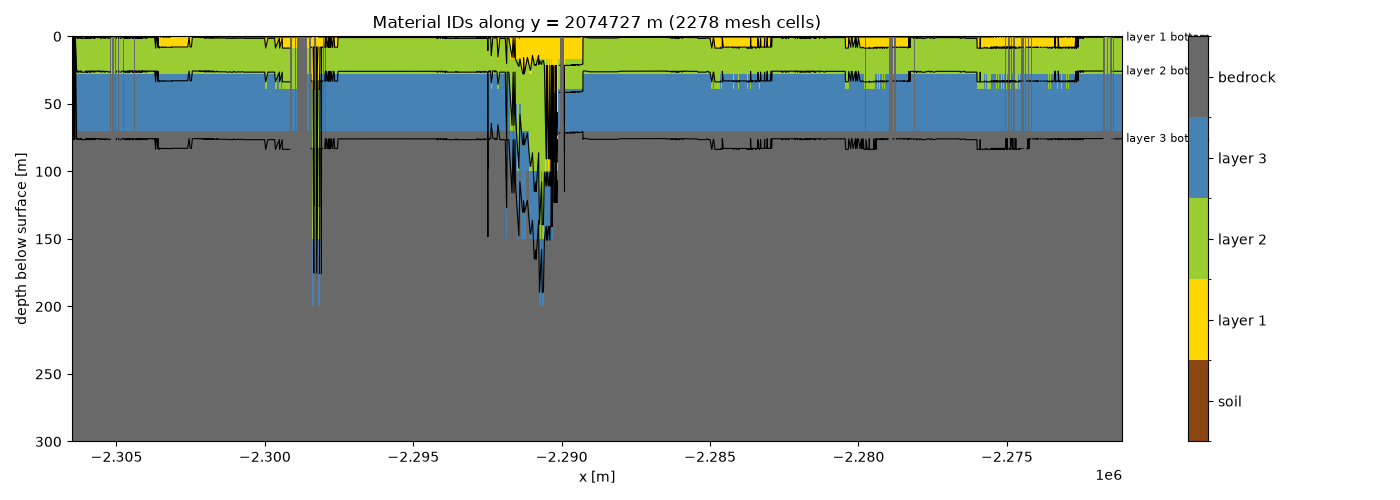

In [56]:
### Cross-section of material IDs along a west-east line through the mesh

from matplotlib.colors import ListedColormap, BoundaryNorm

y_section = np.median(m2.centroids[:, 1])   # change to move the section north or south
band = 300.                                  # half-width [m] of the strip of cells used

in_band = np.where(np.abs(m2.centroids[:, 1] - y_section) < band)[0]
in_band = in_band[np.argsort(m2.centroids[in_band, 0])]
x_section = m2.centroids[in_band, 0]
z_edges = np.concatenate([[0.], np.cumsum(dz_cells)])

# Collapse the soil IDs into one class so the geologic layers are easy to read
section_ids = mat_cols[in_band].T
section = np.zeros(section_ids.shape, dtype=int)   # 0 = soil
for k, mat_id in enumerate([MAT_ID_LAYER1, MAT_ID_LAYER2, MAT_ID_LAYER3, MAT_ID_BEDROCK], start=1):
    section[section_ids == mat_id] = k
cmap = ListedColormap(['saddlebrown', 'gold', 'yellowgreen', 'steelblue', 'dimgrey'])
norm = BoundaryNorm(np.arange(-0.5, 5.5), cmap.N)

fig, ax = plt.subplots(figsize=(14, 5))
# x edges halfway between neighbouring cell centroids
x_edges = np.concatenate([[x_section[0]], 0.5 * (x_section[1:] + x_section[:-1]), [x_section[-1]]])
pc = ax.pcolormesh(x_edges, z_edges, section, cmap=cmap, norm=norm)

# Requested layer bottoms from the rasters, for comparison with the extruded cells
for bottom, label in [(layer1_bottom, 'layer 1 bottom'), (layer2_bottom, 'layer 2 bottom'), (layer3_bottom, 'layer 3 bottom')]:
    ax.plot(x_section, bottom[in_band], 'k-', lw=0.8)
    ax.text(x_section[-1], bottom[in_band][-1], f' {label}', va='center', fontsize=8)

ax.set_ylim(mesh_depth, 0)
ax.set_xlabel('x [m]')
ax.set_ylabel('depth below surface [m]')
ax.set_title(f'Material IDs along y = {y_section:.0f} m ({len(in_band)} mesh cells)')
cbar = fig.colorbar(pc, ax=ax, ticks=range(5))
cbar.ax.set_yticklabels(['soil', 'layer 1', 'layer 2', 'layer 3', 'bedrock'])
plt.tight_layout()
plt.show()


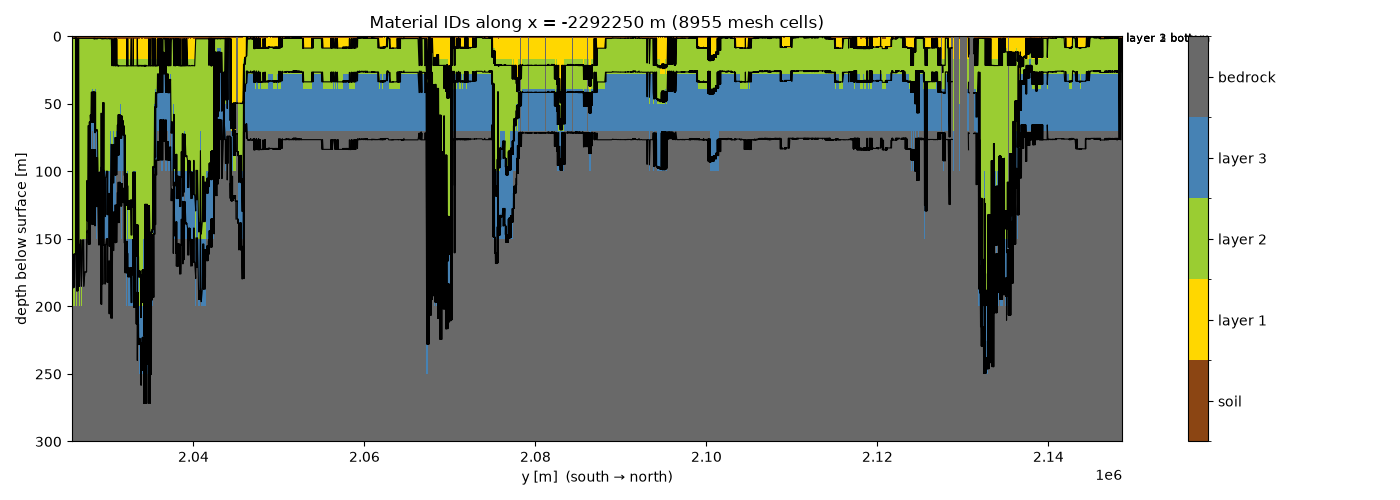

In [57]:
### Cross-section of material IDs along a north-south line through the mesh

from matplotlib.colors import ListedColormap, BoundaryNorm

x_section0 = np.median(m2.centroids[:, 0])   # easting [m] of the line; change to move it west or east
band = 300.                                   # half-width [m] of the strip of cells used

in_band = np.where(np.abs(m2.centroids[:, 0] - x_section0) < band)[0]
in_band = in_band[np.argsort(m2.centroids[in_band, 1])]   # order south to north
y_section = m2.centroids[in_band, 1]
z_edges = np.concatenate([[0.], np.cumsum(dz_cells)])

# Collapse the soil IDs into one class so the geologic layers are easy to read
section_ids = mat_cols[in_band].T
section = np.zeros(section_ids.shape, dtype=int)   # 0 = soil
for k, mat_id in enumerate([MAT_ID_LAYER1, MAT_ID_LAYER2, MAT_ID_LAYER3, MAT_ID_BEDROCK], start=1):
    section[section_ids == mat_id] = k
cmap = ListedColormap(['saddlebrown', 'gold', 'yellowgreen', 'steelblue', 'dimgrey'])
norm = BoundaryNorm(np.arange(-0.5, 5.5), cmap.N)

fig, ax = plt.subplots(figsize=(14, 5))
# y edges halfway between neighbouring cell centroids
y_edges = np.concatenate([[y_section[0]], 0.5 * (y_section[1:] + y_section[:-1]), [y_section[-1]]])
pc = ax.pcolormesh(y_edges, z_edges, section, cmap=cmap, norm=norm)

# Requested layer bottoms from the rasters, for comparison with the extruded cells
for bottom, label in [(layer1_bottom, 'layer 1 bottom'), (layer2_bottom, 'layer 2 bottom'), (layer3_bottom, 'layer 3 bottom')]:
    ax.plot(y_section, bottom[in_band], 'k-', lw=0.8)
    ax.text(y_section[-1], bottom[in_band][-1], f' {label}', va='center', fontsize=8)

ax.set_ylim(mesh_depth, 0)
ax.set_xlabel('y [m]  (south → north)')
ax.set_ylabel('depth below surface [m]')
ax.set_title(f'Material IDs along x = {x_section0:.0f} m ({len(in_band)} mesh cells)')
cbar = fig.colorbar(pc, ax=ax, ticks=range(5))
cbar.ax.set_yticklabels(['soil', 'layer 1', 'layer 2', 'layer 3', 'bedrock'])
plt.tight_layout()
plt.show()


In [58]:
### Save the properties of the materials used in the mesh, in the format 07_input_files expects
# 07 reads filenames['subsurface properties'] and indexes the table by 'ats_id'.
# Uses the literal watershed name because `name` is overwritten by the loop in the mesh-check cell above.
props_out = subsurface_props_used.drop(columns='geometry', errors='ignore').reset_index(names='ats_id')

# every material in the mesh needs a name and the hydraulic properties 07 reads
required = ['name', 'porosity [-]', 'permeability [m^2]', 'van Genuchten alpha [Pa^-1]',
            'van Genuchten n [-]', 'residual saturation [-]']
assert not props_out[required].isna().any().any(), props_out[props_out[required].isna().any(axis=1)]

props_out.to_csv(toOutput('subsurface properties', 'RussianRiver_subsurface_props_used.csv'), index=False)

# re-save the filename index so 07 sees the new key
with open(toOutput('06_output_filenames', '06_output_filenames.txt'), 'wb') as fid:
    pickle.dump(output_filenames, fid)

props_out[['ats_id'] + required]

,ats_id,name,porosity [-],permeability [m^2],van Genuchten alpha [Pa^-1],van Genuchten n [-],residual saturation [-]
0,201,geologic_layer_1,0.300000,1.000000e-12,0.000100,1.500000,0.100000
1,202,geologic_layer_2,0.250000,1.000000e-13,0.000100,1.400000,0.100000
2,203,geologic_layer_3,0.200000,5.000000e-14,0.000010,1.300000,0.150000
3,999,bedrock,0.050000,1.000000e-16,0.000019,1.500000,0.010000
4,1000,NRCS-458924_NRCS-458925_NRCS-458926_NRCS-16074...,0.383571,2.019751e-13,0.000083,1.313487,0.262417
...,...,...,...,...,...,...,...
311,1307,NRCS-813988,0.434094,4.065767e-13,0.000082,1.327769,0.249468
312,1308,NRCS-2747732,0.363651,7.078058e-13,0.000075,1.385508,0.227798
313,1309,NRCS-3115269_NRCS-3115293_NRCS-3115318,0.316789,8.865366e-13,0.000085,1.391169,0.218087
314,1310,NRCS-3251971_NRCS-3251972,0.439850,1.636090e-13,0.000085,1.308479,0.265837
